[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vvvvvivekkk/AI-Engineer/blob/main/03-math-for-ai/notebooks/02-matrices.ipynb)

# 02 · Matrices: data tables and transformations

**What you will learn**
- a **matrix** as a table of data (rows = examples, columns = features)
- **transpose** and shapes
- matrix × vector = many dot products at once
- matrix × matrix, the **shape rule**, and why order matters
- a 2×2 matrix as a **transformation** that moves the whole plane
- one neural-network layer: `X @ W + b`

## 0. Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=3, suppress=True)   # print numbers neatly
NAVY, TEAL, RED, ORANGE = "#1B263B", "#0F9D9A", "#D1495B", "#F28C28"   # course colours

## 1. A matrix as a data table

Rows = students, columns = maths, science, english. This is the "X" matrix of machine learning: one row per example, one column per **feature**.

In [2]:
scores = np.array([
    [80, 72, 65],
    [65, 90, 70],
    [70, 88, 92],
])
print(scores)
print("shape (rows, columns):", scores.shape)
print("student 1 as a vector:", scores[1])
print("science column:       ", scores[:, 1])

[[80 72 65]
 [65 90 70]
 [70 88 92]]
shape (rows, columns): (3, 3)
student 1 as a vector: [65 90 70]
science column:        [72 90 88]


## 2. Transpose: flip rows and columns

`.T` turns a (3 × 2) matrix into (2 × 3).

In [3]:
M = np.array([[1, 2], [3, 4], [5, 6]])
print(M, M.shape)
print(M.T, M.T.shape)

[[1 2]
 [3 4]
 [5 6]] (3, 2)
[[1 3 5]
 [2 4 6]] (2, 3)


## 3. Matrix × vector = one dot product per row

Final grade weights `[0.5, 0.3, 0.2]`. `scores @ weights` dots every student's row with the weights. Compare with the loop version.

In [4]:
weights = np.array([0.5, 0.3, 0.2])
print("all at once:", scores @ weights)
print("row by row: ", [float(row @ weights) for row in scores])

all at once: [74.6 73.5 79.8]
row by row:  [74.60000000000001, 73.5, 79.8]


## 4. Matrix × matrix

Each cell of the answer = (a row of the left matrix) · (a column of the right matrix).
**Restaurant example.** Left: what each table ordered (rows = tables, columns = dishes). Right: each dish's price and calories (rows = dishes). The answer: each table's total price and calories.

In [5]:
orders = np.array([      # dosa, idli, coffee
    [2, 0, 2],              # table 1
    [1, 3, 1],              # table 2
])
dish_info = np.array([     # price, calories
    [80, 350],              # dosa
    [50, 150],              # idli
    [30, 100],              # coffee
])
totals = orders @ dish_info
print(totals)
print("shapes:", orders.shape, "@", dish_info.shape, "->", totals.shape)
print("check table 1 price by hand:", 2 * 80 + 0 * 50 + 2 * 30)

[[220 900]
 [260 900]]
shapes: (2, 3) @ (3, 2) -> (2, 2)
check table 1 price by hand: 220


## 5. The shape rule (and the error you will see a lot)

(m × **n**) @ (**n** × p) works and gives (m × p). If the inner numbers differ, NumPy raises an error. We catch it with `try/except` so the notebook keeps running.

In [6]:
A = np.ones((3, 2))
B = np.ones((3, 4))
try:
    A @ B
except ValueError as e:
    print("Error:", e)
print("Fix by transposing A:", (A.T @ B).shape)

Error: matmul: Input operand 1 has a mismatch in its core dimension 0, with gufunc signature (n?,k),(k,m?)->(n?,m?) (size 3 is different from 2)
Fix by transposing A: (2, 4)


## 6. Order matters: A @ B is usually not B @ A

In [7]:
A = np.array([[1, 2], [3, 4]])
B = np.array([[0, 1], [1, 0]])
print("A @ B =\n", A @ B)
print("B @ A =\n", B @ A)

A @ B =
 [[2 1]
 [4 3]]
B @ A =
 [[3 4]
 [1 2]]


## 7. A matrix as a transformation

Multiply every point of a square grid by a 2×2 matrix and plot where the points go. Change the matrix in the cell and rerun to experiment.

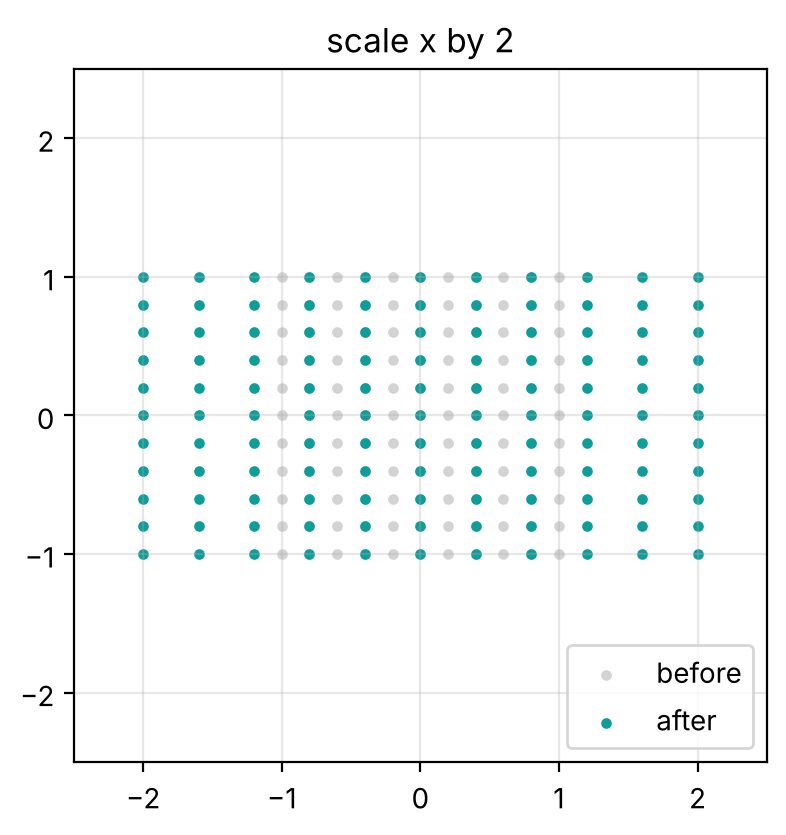

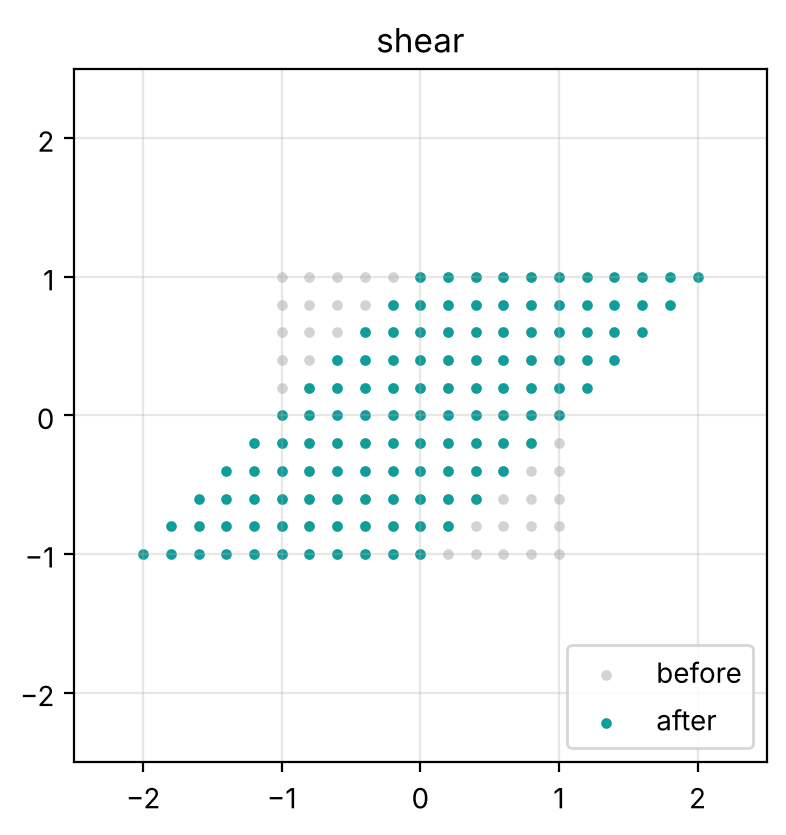

In [8]:
def show_transform(M, title):
    pts = np.array([[x, y] for x in np.linspace(-1, 1, 11) for y in np.linspace(-1, 1, 11)])
    moved = pts @ M.T                      # same as applying M to every point
    fig, ax = plt.subplots(figsize=(4.5, 4.5))
    ax.scatter(pts[:, 0], pts[:, 1], s=8, color="lightgrey", label="before")
    ax.scatter(moved[:, 0], moved[:, 1], s=8, color=TEAL, label="after")
    ax.set_xlim(-2.5, 2.5); ax.set_ylim(-2.5, 2.5); ax.set_aspect("equal"); ax.grid(alpha=0.3)
    ax.set_title(title); ax.legend(loc="lower right"); plt.show()

show_transform(np.array([[2, 0], [0, 1]]), "scale x by 2")
show_transform(np.array([[1, 1], [0, 1]]), "shear")

Rotation by an angle θ uses cos and sin. Here 45°: the grid turns into a diamond.

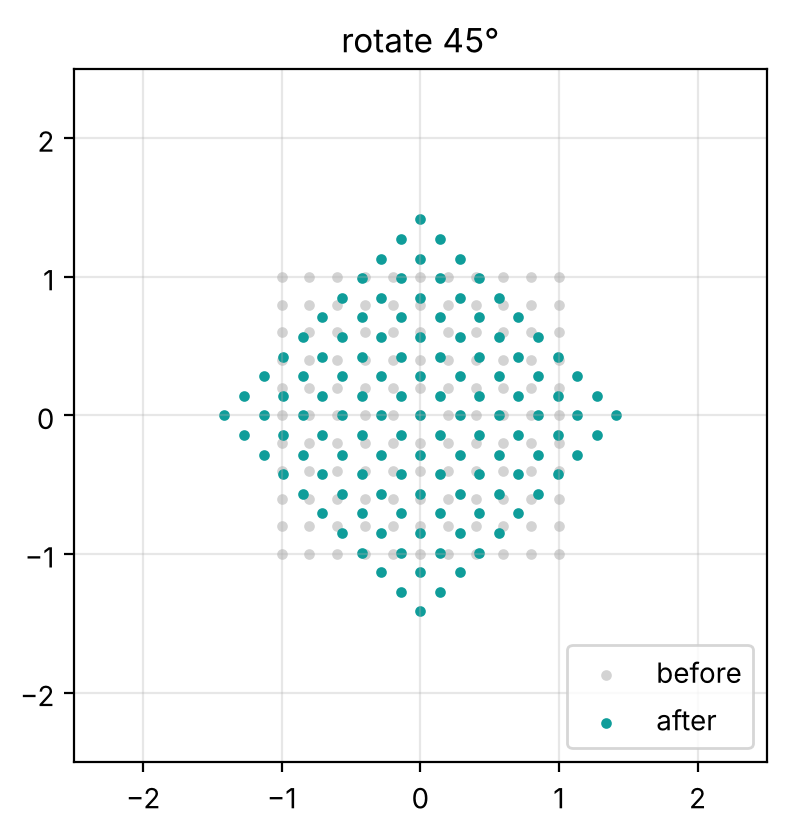

In [9]:
theta = np.deg2rad(45)
R = np.array([[np.cos(theta), -np.sin(theta)],
              [np.sin(theta),  np.cos(theta)]])
show_transform(R, "rotate 45°")

## 8. The identity matrix: "do nothing"

`np.eye(n)` has 1s on the diagonal and 0s elsewhere. Multiplying by it changes nothing, like multiplying a number by 1.

In [10]:
I = np.eye(3)
print(I)
print("scores @ I equals scores?", np.array_equal(scores @ I, scores))

[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
scores @ I equals scores? True


## 9. One neural-network layer: `X @ W + b`

- `X`: 4 examples × 3 features
- `W`: 3 features × 2 neurons (the model learns these numbers; here random)
- `b`: one bias per neuron, added to every row by broadcasting

The output has one row per example and one column per neuron.

In [11]:
rng = np.random.default_rng(0)
X = rng.normal(size=(4, 3))
W = rng.normal(size=(3, 2))
b = np.array([0.1, -0.2])
out = X @ W + b
print("X", X.shape, "@ W", W.shape, "+ b", b.shape, "->", out.shape)
print(out)
relu = np.maximum(out, 0)       # a common "squashing" step: negatives become 0
print("after ReLU:\n", relu)

X (4, 3) @ W (3, 2) + b (2,) -> (4, 2)
[[-0.376 -0.333]
 [ 0.327  0.055]
 [-3.729 -0.956]
 [ 3.796  0.52 ]]
after ReLU:
 [[0.    0.   ]
 [0.327 0.055]
 [0.    0.   ]
 [3.796 0.52 ]]


## Your turn
1. Add a third table to `orders` (any numbers) and recompute `totals`. What is the new shape?
2. Find a 2×2 matrix that flips the grid upside down (mirror in the x-axis) and check it with `show_transform`.

## Recap
Matrix = table of numbers. Matrix @ vector = a dot product per row. Matrix @ matrix = rows of A · columns of B; inner shapes must match. A 2×2 matrix moves the plane. A neural-network layer is `X @ W + b`.